In [18]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import keras_tuner
from datetime import datetime
import os
import random
from matplotlib import pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import log_loss
from scipy.optimize import minimize, LinearConstraint
from itertools import permutations 
from sklearn.model_selection import KFold
%matplotlib inline

In [19]:
# data processing
def col_to_array_by_group(df: pd.DataFrame, col_name: str, group_name = "race_id", index_name = "horse_no", padding = 0):
    data_array = df.pivot_table(index = group_name, columns = [index_name], values = [col_name]).sort_index(axis = 0).sort_index(axis = 1).to_numpy()
    data_array[np.isnan(data_array)] = padding
    return data_array

def generate_data_array(df: pd.DataFrame, predictor_names: list, response_name: str, group_name = "race_id", index_name = "horse_no", padding = 0):
    """Generate arrays required for Tensorflow model fitting"""
    X_array = np.array([col_to_array_by_group(df, i, group_name = group_name, index_name = index_name) for i in predictor_names])
    X_array = X_array.swapaxes(0,1).swapaxes(1,2)
    y_array = col_to_array_by_group(df, response_name, group_name = group_name, index_name = index_name, padding = np.nan)
    mask = True^np.isnan(y_array)
    y_array[np.isnan(y_array)] = padding
    y_array = y_array.astype(int)
    return X_array, y_array, mask

def generate_implied_prob(df: pd.DataFrame, odds_name: str, group_name = "race_id", index_name = "horse_no", padding = 0):
    """Generate probability estimates implied by public win odds"""
    df_copy = df.copy()
    df_copy[odds_name] = 1/df_copy[odds_name]
    proba_mat = col_to_array_by_group(df_copy, odds_name, group_name = group_name, index_name = index_name, padding = padding)
    return proba_mat/proba_mat.sum(axis = 1)[:, None]

def explode_data(X, y, mask, depth = 1):
    X_sub = []
    y_sub = []
    mask_sub = []
    for i in range(depth):
        X_sub.append(X*(y[:,:,None] > i))
        y_sub.append((y == i + 1).astype(int))
        mask_sub.append(mask*(y > i))
    return np.concatenate(X_sub, axis = 0), np.concatenate(y_sub, axis = 0), np.concatenate(mask_sub, axis = 0)

In [20]:
# Performance evaluation
def neg_loglik(y, proba_mat):
    return(np.mean(-np.log(proba_mat[y == 1])))

def performance(strategy, proba_mat, odds_mat, y_mat, initial_amount = 100.0, return_mode = "plot", **kwargs):
    amount = [initial_amount]
    bet = []
    payoff = []
    ruin = False
    for proba, odds, y in zip(proba_mat, odds_mat, y_mat):
        if ruin == False:
            bet.append(strategy(proba, odds, amount, **kwargs))
            payoff.append(strategy(proba, odds, amount, **kwargs)*odds*y)
            amount.append(max(amount[-1] + sum(payoff[-1] - bet[-1]), 0.0))
            if amount[-1] <= 0.01:
                ruin = True
        else:
            bet.append(np.zeros_like(proba))
            payoff.append(np.zeros_like(proba))
            amount.append(0.0)
    if return_mode == "plot":
        return plt.plot(amount)
    elif return_mode == "result":
        return np.array(amount), np.array(bet), np.array(payoff)
    elif return_mode == "full":
        return plt.plot(amount), np.array(amount), np.array(bet), np.array(payoff)

def fixed_among_positive_advantage(proba, odds, amount, proportion = 0.01, threshold = 0):
    advantage = proba*odds-1
    bet = amount[0]*proportion*(advantage > threshold)
    return bet

def fixed_proportion_among_positive_advantage(proba, odds, amount, proportion = 0.01, threshold = 0):
    advantage = proba*odds-1
    bet = amount[-1]*proportion*(advantage > threshold)
    return bet

def kelly(proba, odds, amount, threshold = 0, partial = 1.0):
    def neg_expected_log_wealth(f, proba, odds):
        wealth = 1 + (np.diag(odds) - 1).dot(f)
        wealth = wealth + 1e-6
        log_return = np.log(wealth)
        out = -proba.dot(log_return)
        return out
    advantage = proba*odds-1
    constriant_matrix = np.identity(len(odds))
    constriant_matrix = np.concatenate([constriant_matrix, np.ones_like(odds)[None,:]])
    result = minimize(neg_expected_log_wealth, np.ones(len(odds))/len(odds), args = (proba, odds), constraints=LinearConstraint(constriant_matrix, lb = 0, ub = 1))
    fraction = result.x
    fraction = fraction*(fraction > 1e-6)*(advantage > threshold)
    bet = amount[-1]*partial*fraction
    return bet

def chi_sq_table(expected, actual, cut_pts):
    df_chi_sq = pd.DataFrame({"expected": expected, "actual": actual})
    df_chi_sq = df_chi_sq.query("expected > 0").reset_index(drop = True)

    df_chi_sq["bin"] = pd.cut(df_chi_sq.expected, cut_pts)

    chi_sq_table = df_chi_sq.groupby("bin")[["expected", "actual"]].sum()
    chi_sq_table["normalized_diff"] = (chi_sq_table.actual - chi_sq_table.expected)/np.sqrt(chi_sq_table.expected)
    return chi_sq_table, sum(chi_sq_table.normalized_diff**2)

In [21]:
def compare_threshold(strategy, proba_mat, odds_mat, y_mat, threshold_grid, **kwargs):
    result = []
    for threshold in threshold_grid:
        amounts = performance(strategy = strategy, 
                            proba_mat = proba_mat, 
                            odds_mat = odds_mat, 
                            y_mat = y_mat, threshold = threshold, return_mode = "result", **kwargs)[0]
        result.append(amounts[-1]/amounts[0] - 1)
    return result

In [22]:
def get_order_proba(win_proba_vec: np.array, order: tuple, correction_factors = None):
    out = 1
    order_list = list(order)
    for i in range(len(order_list)):
        if correction_factors is None:
            corrected_win_proba_vec = win_proba_vec
        else:
            corrected_win_proba_vec = win_proba_vec**correction_factors[i]
            corrected_win_proba_vec = corrected_win_proba_vec/sum(corrected_win_proba_vec)
        out *= corrected_win_proba_vec[order_list[i]]/(1 - sum(corrected_win_proba_vec[order_list[:i]]))
    return out

def get_place_proba(proba_dict: dict, index: int):
    return(sum([proba_dict[order] if index in order else 0 for order in proba_dict]))

def get_quinella_proba(proba_dict: dict, indices: tuple):
    return(sum([proba_dict[order] if (indices[0] in order[:2])&(indices[1] in order[:2]) else 0 for order in proba_dict]))

def get_quinella_place_proba(proba_dict: dict, indices: tuple):
    return(sum([proba_dict[order] if (indices[0] in order)&(indices[1] in order) else 0 for order in proba_dict]))

def generate_other_pools(win_proba_mat, y_mat, place_odds, q_odds, qp_odds):
    proba_place = place_odds.copy()
    proba_q = q_odds.copy()
    proba_qp = qp_odds.copy()
    y_mat_place = place_odds.copy()
    y_mat_q = q_odds.copy()
    y_mat_qp = qp_odds.copy()
    index_place = place_odds.columns
    orders_q = q_odds.columns
    orders_qp = qp_odds.columns
    for i, win_proba_vec in enumerate(win_proba_mat):
        # Constuct proba_dict
        proba_dict = {}
        for order in permutations(range(14), 3):
            proba_dict[(order[0]+1, order[1]+1, order[2]+1)] = get_order_proba(win_proba_vec, order)
        
        # Place
        proba_place.iloc[i,:] = [get_place_proba(proba_dict, index) for index in index_place]
        y_mat_place.iloc[i,:] = [(y_mat[i, index-1] >= 1)&(y_mat[i, index-1] <=3) for index in index_place]

        # Quinella
        proba_q.iloc[i,:] = [get_quinella_proba(proba_dict, order) for order in orders_q]
        y_mat_q.iloc[i,:] = [(y_mat[i, order[0]-1] in [1,2])&(y_mat[i, order[1]-1] in [1,2]) for order in orders_q]

        # Quinella place
        proba_qp.iloc[i,:] = [get_quinella_place_proba(proba_dict, order) for order in orders_qp]
        y_mat_qp.iloc[i,:] = [(y_mat[i, order[0]-1] in [1,2,3])&(y_mat[i, order[1]-1] in [1,2,3]) for order in orders_qp]
        if (i + 1) % 10 == 0:
            print(f"Race {i + 1} completed ", end = '\r')
    print("All completed     ", end = '\r')
    return proba_place.to_numpy(), y_mat_place.to_numpy(), proba_q.to_numpy(), y_mat_q.to_numpy(), proba_qp.to_numpy(), y_mat_qp.to_numpy()

# Feature Engineering

In [23]:
combined = pd.read_csv("combined.csv", low_memory=False)
place_odds = pd.read_csv("place_odds.csv")
q_qp_odds = pd.read_csv("q_qp_odds.csv", low_memory=False)
q_qp_odds.replace(["---", 'SCR', np.nan], 0, inplace = True)

In [24]:
q_qp_odds = pd.read_csv("q_qp_odds.csv", low_memory=False)
q_qp_odds.replace(["---", 'SCR', np.nan], 0, inplace = True)
q_qp_odds[["q_odds", "qp_odds"]] = q_qp_odds[["q_odds", "qp_odds"]].astype(float)
q_qp_odds.date = pd.to_datetime(q_qp_odds.date)

In [25]:
combined = combined.merge(place_odds, on = ["date", "race_no", "horse_no"], how = "left")
combined.replace(['-', "--", "---"], np.nan, inplace=True)
combined = combined.query("place != 'VOID'")
combined["won"] = combined.place.apply(lambda x: x in ['1', "1 DH"]).astype(float)

In [26]:
combined["win_odds"] = combined["win_odds"].astype(float)
combined["place_odds"] = combined["place_odds"].astype(float)
combined["log_odds"] = np.log(combined.win_odds)
combined["log_place_odds"] = np.log(combined.place_odds)

In [27]:
combined["place"] = combined.place.str.replace(" DH", '')
special_conditions = ['WV', 'TNP', 'UR', 'WX', 'WV-A', 'DISQ', 'PU', 'FE', 'WX-A', 'DNF', 'WXNR']
combined["special_condition"] = combined.place.apply(lambda x: x if x in special_conditions else np.nan)
combined.special_condition.replace(np.nan, "N/A", inplace = True)
combined["place"] = combined.place.apply(lambda x: np.nan if x in special_conditions else x)
combined["place"] = combined.place.astype(float)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_27808\330017236.py:4: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  combined.special_condition.replace(np.nan, "N/A", inplace = True)


In [28]:
combined = combined.astype({"actual_weight": float, 
                            "declare_weight": float,
                            "draw": float,
                            "rating": float})

In [29]:
combined.date = pd.to_datetime(combined.date)
combined.sort_values(by = ["date", "race_no", "place"], inplace = True)
combined.reset_index(drop = True, inplace = True)

In [30]:
combined["race_id"] = combined.groupby(["date", "race_no"]).ngroup()
combined["start_year"] = combined.horse_url.apply(lambda x: float(x[79:83]) if type(x) == str else x)
combined["race_start_year"] = combined.groupby("race_id").start_year.transform(min)
combined[["venue", "course", "course_config"]] = combined.venue_full.str.split(' / ', expand = True)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_27808\3366480144.py:3: FutureWarning: The provided callable <built-in function min> is currently using SeriesGroupBy.min. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "min" instead.
  combined["race_start_year"] = combined.groupby("race_id").start_year.transform(min)


In [31]:
combined[['race_id', 'horse_no', 'place', 'win_odds']]

,race_id,horse_no,place,win_odds
0,0,7.0,1.0,54.0
1,0,1.0,2.0,5.4
2,0,12.0,3.0,3.0
3,0,5.0,4.0,55.0
4,0,8.0,5.0,32.0
...,...,...,...,...
98874,7958,13.0,10.0,11.0
98875,7958,14.0,11.0,31.0
98876,7958,3.0,12.0,28.0
98877,7958,10.0,13.0,70.0


### Gear

In [32]:
gear = combined.gear.apply(lambda x: x.replace('1','').replace('2','').split('/') if type(x) == str else [])
combined["n_gear"] = gear.apply(len)
combined["n_gear_change"] = combined.groupby("horse_code").n_gear.transform(lambda x: x.diff(1)).replace(np.nan, 0)
# for g in ['B', 'BO', 'CO', 'CP', 'E', 'H', 'P', 'PC', 'PS', 'SB', 'SR', 'TT', 'V', 'VO', 'XB']:
#     combined[g] = gear.apply(lambda x: g in x if type(x) == list else False).astype(float)

### Average Standard Time

In [33]:
# standardized performance
dict_venue = combined.dropna(subset=['distance', 'course', 'going']).groupby("race_id")[['distance', 'course', 'going']].apply(lambda x: x.iloc[0,:]).T.to_dict()
dict_mean_std = {}
for race_id in dict_venue:
    df = combined.query(f"distance == {dict_venue[race_id]['distance']} & course == '{dict_venue[race_id]['course']}' & going == '{dict_venue[race_id]['going']}'")
    focal = df.query(f"race_id <= {race_id}").time
    dict_mean_std[race_id] = [focal.mean(), focal.std()]
    print(str(race_id) + "    ", end = '\r')

m = combined.race_id.apply(lambda x: dict_mean_std[x][0])
s = combined.race_id.apply(lambda x: dict_mean_std[x][1])
combined["standard_time"] = (combined.time - m)/s
combined["avg_std_time"] = combined.groupby("horse_code").standard_time.transform(lambda x: x.shift().expanding().mean())

### Average Standard Place

In [34]:
combined["std_place"] = (combined.place - 1)/(combined.groupby(["race_id"]).place.transform(max) - 1)
combined["avg_std_place"] = combined.groupby("horse_code").std_place.transform(lambda x: x.shift().expanding().mean())

C:\Users\Administrator\AppData\Local\Temp\ipykernel_27808\2830491156.py:1: FutureWarning: The provided callable <built-in function max> is currently using SeriesGroupBy.max. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "max" instead.
  combined["std_place"] = (combined.place - 1)/(combined.groupby(["race_id"]).place.transform(max) - 1)


### Number of days since last race

In [35]:
combined["relative_day"] = combined.date.apply(lambda x: (x - datetime(2015, 1, 1)).days)
combined["day_since"] = combined.groupby(["horse_code"]).relative_day.transform(lambda x: x.diff(1))
combined["log_day_since"] = np.log(combined["day_since"] + 1)

### Number of days since first race

In [36]:
combined["day_since_start"] = (combined.date - combined.groupby("horse_code").date.transform(lambda x: x.iloc[0]))/np.timedelta64(1, 'D')
combined["log_day_since_start"] = np.log(combined["day_since_start"] + 1)

### Win Rate

In [37]:
# decay_factor = np.log(2)/365
decay_factor = 0

In [38]:
# combined["intercept"] = 1
# combined["intercept_decay"] = combined.intercept*np.exp(decay_factor*combined.relative_day)
# combined["n_race_decay"] = combined.groupby("horse_code").intercept_decay.transform(lambda x: x.shift().expanding().sum())/np.exp(decay_factor*combined.relative_day)
# combined["n_race_exp_decay"].replace(np.nan, 0, inplace = True)
# combined.drop(columns = "intercept_decay", inplace = True)

In [39]:
# combined["won_decay"] = combined.won*np.exp(decay_factor*combined.relative_day)
# combined["n_won_decay"] = combined.groupby("horse_code").won_decay.transform(lambda x: x.shift().expanding().sum())/np.exp(decay_factor*combined.relative_day)
# combined["n_won_decay"].replace(np.nan, 0, inplace = True)
# combined["win_rate_decay"] = combined["n_won_decay"]/combined.groupby("horse_code").won.transform(lambda x: x.shift().expanding().count())
# combined["win_rate_decay"].replace(np.nan, 0, inplace = True)
# combined.drop(columns = "won_decay", inplace = True)

In [40]:
window_size = 3
combined["horse_win_rate"+str(window_size)] = combined.groupby("horse_code").won.transform(lambda x: x.shift().rolling(window_size, min_periods = 0).mean())
combined["jockey_win_rate"+str(window_size)] = combined.groupby("jockey").won.transform(lambda x: x.shift().rolling(window_size, min_periods = 0).mean())

combined["is_place"] = (combined.place >= 1)*(combined.place <= 3)
combined["horse_place_rate"+str(window_size)] = combined.groupby("horse_code").is_place.transform(lambda x: x.shift().rolling(window_size, min_periods = 0).mean())
combined["jockey_place_rate"+str(window_size)] = combined.groupby("jockey").is_place.transform(lambda x: x.shift().rolling(window_size, min_periods = 0).mean())

### log difference of weights 

In [41]:
combined["actual_wt_log_ratio"] = combined.groupby("horse_code").actual_weight.transform(lambda x: np.log(x).diff(1))
combined["declare_wt_log_ratio"] = combined.groupby("horse_code").declare_weight.transform(lambda x: np.log(x).diff(1))

### Number of special conditions in past

In [42]:
combined = combined.copy()

In [43]:
combined["condition_wv"] = combined.special_condition.apply(lambda x: "WV" in x).astype(float)
combined["condition_wx"] = combined.special_condition.apply(lambda x: "WX" in x).astype(float)
combined["condition_in_race"] = combined.special_condition.apply(lambda x: x in ['UR', 'PU', 'FE', 'DNF']).astype(float)

In [44]:
combined["n_wv3"] = combined.groupby("horse_code").condition_wv.transform(lambda x: x.shift().rolling(3, min_periods = 0).sum())
combined["n_wx3"] = combined.groupby("horse_code").condition_wx.transform(lambda x: x.shift().rolling(3, min_periods = 0).sum())
combined["n_condition_in_race3"] = combined.groupby("horse_code").condition_in_race.transform(lambda x: x.shift().rolling(3, min_periods = 0).sum())

### Categorical variables encoding

In [45]:
combined.sex.replace(['Gelding', 'Horse', 'Mare', 'Colt', 'Filly', 'Rig'], 
                     [1,2,2,2,0,0], inplace = True)
combined.country_of_origin.replace(['SPA', 'ARG', 'BRZ', 'ITY', 'SAF', 'GER', 'GB', 'FR', 'JPN', 'IRE','NZ', 'AUS', 'USA', 'CHI'],
                                   [0,1,1,1,1,2,2,2,2,2,2,2,2,3], inplace = True)
combined.colour.replace(['Roan', 'Grey/Roan', 'Dark Bay', 'Brown/Grey', 'Black', 'Chestnut', 'Bay', 'Brown', 'Grey', 'Bay/Brown', 'Bay/Grey', 'Dark Bay/Brown'],
                        [0,0,0,1,1,1,1,1,1,1,1,2], inplace = True)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_27808\3861699052.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  combined.sex.replace(['Gelding', 'Horse', 'Mare', 'Colt', 'Filly', 'Rig'],
C:\Users\Administrator\AppData\Local\Temp\ipykernel_27808\3861699052.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downca

In [46]:
convert_dict = {'GF':1,
                'G':5/6,
                'GY':4/6,
                'Y':3/6,
                'YS':2/6,
                'S':1/6,
                'H':0,
                'FT':1,
                'GD':0.5,
                'WF':0.5,
                'WS':0}
combined.going.replace(convert_dict, inplace = True)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_27808\2585287581.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  combined.going.replace(convert_dict, inplace = True)
C:\Users\Administrator\AppData\Local\Temp\ipykernel_27808\2585287581.py:12: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  com

In [47]:
combined["is_st"] = (combined["venue"] == "ST").astype(float)
combined["is_turf"] = (combined["course"] == "Turf").astype(float)

### Course similarity

In [48]:
ss = combined.groupby("horse_code").distance.transform(lambda x: (x**2).shift().rolling(3, min_periods = 1).sum())
sums = combined.groupby("horse_code").distance.transform(lambda x: x.shift().rolling(3, min_periods = 1).sum())
n_races3 = combined.groupby("horse_code").distance.transform(lambda x: x.shift().rolling(3, min_periods = 1).count())
combined["distance_dis_sim"] = np.sqrt((ss - 2*combined.distance*sums + n_races3*combined.distance**2)/n_races3)

In [49]:
combined["is_awt"] = (combined.course == "AWT").astype(float)
combined["n_awt"] = combined.groupby("horse_code").is_awt.transform(lambda x: x.shift().expanding().sum())

In [50]:
n_races = combined.groupby("horse_code").distance.transform(lambda x: x.shift().expanding().count())
combined["n_turf"] = n_races - combined["n_awt"]

In [51]:
combined["n_awt"].replace(np.nan, 0, inplace=True)
combined["n_turf"].replace(np.nan, 0, inplace=True)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_27808\78184569.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  combined["n_awt"].replace(np.nan, 0, inplace=True)
C:\Users\Administrator\AppData\Local\Temp\ipykernel_27808\78184569.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a 

In [52]:
combined["track_sim"] = combined.is_awt*combined.n_awt + (1-combined.is_awt)*combined.n_turf

### Last odds implied probability

In [53]:
combined["implied_win_proba"] = (1/combined.win_odds)/combined.groupby("race_id").win_odds.transform(lambda x: (1/x).sum())
combined["last_implied_win_proba"] = combined.groupby("horse_code").implied_win_proba.transform(lambda x: x.shift())

In [54]:
combined["log_last_implied_win_proba"] = np.log(combined["last_implied_win_proba"])

In [55]:
combined["is_new_horse"] = (combined.day_since_start == 0).astype(float)

In [56]:
combined

,date,race_no,venue,place,horse_no,horse,jockey,trainer,actual_weight,declare_weight,...,is_turf,distance_dis_sim,is_awt,n_awt,n_turf,track_sim,implied_win_proba,last_implied_win_proba,log_last_implied_win_proba,is_new_horse
0,2015-01-01,1,ST,1.0,7.0,TELEPHATIA,M L Yeung,A Lee,123.0,1049.0,...,1.0,NaN,0.0,0.0,0.0,0.0,0.015123,NaN,NaN,1.0
1,2015-01-01,1,ST,2.0,1.0,NAMJONG TURBO,K C Leung,P O'Sullivan,129.0,1079.0,...,1.0,NaN,0.0,0.0,0.0,0.0,0.151229,NaN,NaN,1.0
2,2015-01-01,1,ST,3.0,12.0,HEAR THE ROAR,M Guyon,S Woods,118.0,1192.0,...,1.0,NaN,0.0,0.0,0.0,0.0,0.272213,NaN,NaN,1.0
3,2015-01-01,1,ST,4.0,5.0,CASA JUNIOR,K Teetan,T K Ng,127.0,1062.0,...,1.0,NaN,0.0,0.0,0.0,0.0,0.014848,NaN,NaN,1.0
4,2015-01-01,1,ST,5.0,8.0,JOYFUL MISSION,O Doleuze,R Gibson,123.0,1091.0,...,1.0,NaN,0.0,0.0,0.0,0.0,0.025520,NaN,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98874,2024-10-01,10,ST,10.0,13.0,ROMAN CROWN,K Teetan,P C Ng,117.0,1101.0,...,1.0,141.421356,0.0,0.0,2.0,2.0,0.073275,0.040534,-3.205611,0.0
98875,2024-10-01,10,ST,11.0,14.0,UNPRESUMING,A Badel,J Size,117.0,1186.0,...,1.0,115.470054,0.0,1.0,10.0,10.0,0.026001,0.039069,-3.242415,0.0
98876,2024-10-01,10,ST,12.0,3.0,BEAUTY GLORY,B Avdulla,A S Cruz,125.0,1128.0,...,1.0,0.000000,0.0,0.0,42.0,42.0,0.028787,0.033841,-3.386071,0.0
98877,2024-10-01,10,ST,13.0,10.0,THE WAY WE WIN,K C Leung,C S Shum,119.0,1084.0,...,1.0,NaN,0.0,0.0,0.0,0.0,0.011515,NaN,NaN,1.0


## Preparation for fitting

In [57]:
df_input = combined[combined.race_start_year >= 2015].reset_index(drop = True)
df_input = df_input.query("place.isnull() == False").query("win_odds.isnull() == False").reset_index(drop = True)
df_input["is_DH"] = df_input.groupby("race_id").place.transform(lambda x: x.nunique()/x.count() < 1)
df_input = df_input[df_input.is_DH == False].reset_index(drop = True)

In [58]:
# Within-race imputation
predictor_names = ['log_odds','log_place_odds','log_last_implied_win_proba','actual_weight','declare_weight','draw','rating','colour','sex','country_of_origin','n_gear','n_gear_change',
                   'log_day_since','log_day_since_start','horse_place_rate3','jockey_place_rate3','actual_wt_log_ratio','declare_wt_log_ratio',
                    'avg_std_time','avg_std_place','n_wv3','n_wx3','n_condition_in_race3','distance_dis_sim','track_sim','is_new_horse']
venue_names = ['race_no','distance','is_st','is_turf','going']
#df_input[predictor_names] = df_input[predictor_names] - df_input.groupby("race_id")[predictor_names].transform(np.mean)
#df_input.replace(np.nan, 0, inplace = True)

In [59]:
df_final = df_input[['race_id','date','special_condition','place','horse_no','horse_code'] + venue_names + predictor_names + ["win_odds", "place_odds", "won"]].copy()

In [60]:
#df_final[predictor_names] = df_final[predictor_names] - df_final.groupby("race_id")[predictor_names].transform(np.mean)

In [61]:
for v in venue_names:
    for p in predictor_names:
        df_final[v + '_times_' + p] = df_final[v]*df_final[p]

extra = []
for v in venue_names:
    for p in predictor_names:
        extra.append(v + '_times_' + p)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_27808\4045647095.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_final[v + '_times_' + p] = df_final[v]*df_final[p]
C:\Users\Administrator\AppData\Local\Temp\ipykernel_27808\4045647095.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_final[v + '_times_' + p] = df_final[v]*df_final[p]
C:\Users\Administrator\AppData\Local\Temp\ipykernel_27808\4045647095.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` man

In [62]:
df_final = df_final.copy()

In [63]:
scaler = StandardScaler()
df_final[predictor_names + venue_names + extra] = scaler.fit_transform(df_final[predictor_names + venue_names + extra])
df_final[predictor_names + venue_names + extra] = df_final[predictor_names + venue_names + extra].replace(np.nan, 0)

In [64]:
df_final[predictor_names + venue_names + extra] = df_final[predictor_names + venue_names + extra].replace(np.nan, 0)

In [65]:
train_start = datetime(2015, 1, 1)
split_time = datetime(2023, 6, 1)
test_end = datetime(2024, 1, 1)
df_train = df_final[(df_final.date >= train_start)&(df_final.date < split_time)].reset_index(drop = True)
df_test = df_final[(df_final.date >= split_time)&(df_final.date < test_end)].reset_index(drop = True)

df_train.sort_values(by = ["race_id", "horse_no"], inplace = True)
df_train.reset_index(drop = True, inplace = True)
df_test.sort_values(by = ["race_id", "horse_no"], inplace = True)
df_test.reset_index(drop = True, inplace = True)

In [66]:
df_train.sort_values(by = ["race_id", "horse_no"], inplace = True)
df_train.reset_index(drop = True, inplace = True)
df_test.sort_values(by = ["race_id", "horse_no"], inplace = True)
df_test.reset_index(drop = True, inplace = True)

In [67]:
q_qp_odds.replace(["---", 'SCR', np.nan], 0, inplace = True)
q_qp_odds[["q_odds", "qp_odds"]] = q_qp_odds[["q_odds", "qp_odds"]].astype(float)
q_qp_odds.date = pd.to_datetime(q_qp_odds.date)

In [68]:
place_odds.date = pd.to_datetime(place_odds.date)
place_odds = place_odds.merge(combined[["race_id", "date", "race_no"]].drop_duplicates(), on = ["date", "race_no"], how = "right").sort_values(by = ["race_id"])

In [69]:
test_race_ids = df_test.race_id.unique()
place_odds = place_odds[place_odds.race_id.apply(lambda x: x in test_race_ids)].reset_index(drop = True)

In [70]:
place_odds["horse_no"] = place_odds["horse_no"].astype(int)

In [71]:
place_odds_test = place_odds.pivot_table(index = "race_id", columns = ["horse_no"], values = "place_odds").replace(np.nan, 0)

TypeError: agg function failed [how->mean,dtype->object]

In [72]:
q_qp_odds = q_qp_odds.merge(combined[["race_id", "date", "race_no"]].drop_duplicates(), on = ["date", "race_no"], how = "right").sort_values(by = ["race_id", "horse_no1", "horse_no2"])
# q_odds_test = q_qp_odds.pivot_table(index = "race_id", columns = ["horse_no1", "horse_no2"], values = "q_odds")
# qp_odds_test = q_qp_odds.pivot_table(index = "race_id", columns = ["horse_no1", "horse_no2"], values = "qp_odds")

In [73]:
test_race_ids = df_test.race_id.unique()
q_qp_odds = q_qp_odds[q_qp_odds.race_id.apply(lambda x: x in test_race_ids)]

In [74]:
q_qp_odds[["horse_no1", "horse_no2"]] = q_qp_odds[["horse_no1", "horse_no2"]].astype(int)

In [75]:
q_odds_test = q_qp_odds.pivot_table(index = "race_id", columns = ["horse_no1", "horse_no2"], values = "q_odds").replace(np.nan, 0)
qp_odds_test = q_qp_odds.pivot_table(index = "race_id", columns = ["horse_no1", "horse_no2"], values = "qp_odds").replace(np.nan, 0)

# Model

In [84]:
predictor_names[2:]

['log_last_implied_win_proba',
 'actual_weight',
 'declare_weight',
 'draw',
 'rating',
 'colour',
 'sex',
 'country_of_origin',
 'n_gear',
 'n_gear_change',
 'log_day_since',
 'log_day_since_start',
 'horse_place_rate3',
 'jockey_place_rate3',
 'actual_wt_log_ratio',
 'declare_wt_log_ratio',
 'avg_std_time',
 'avg_std_place',
 'n_wv3',
 'n_wx3',
 'n_condition_in_race3',
 'distance_dis_sim',
 'track_sim',
 'is_new_horse']

In [85]:
# original
generate_names = predictor_names + extra
generate_names = predictor_names[2:]
X_train, y_train, mask_train = generate_data_array(df_train, generate_names, "place")
X_test, y_test, mask_test = generate_data_array(df_test, generate_names, "place")

# PCA
# X_train, y_train, mask_train = generate_data_array(df_train, "race_id", ["pc" + str(i) for i in range(1, n_left+1)], "won")
# X_test, y_test, mask_test = generate_data_array(df_test, "race_id", ["pc" + str(i) for i in range(1, n_left+1)], "won")

## ConditionalLogit

### Tensorflow

In [85]:
class ConditionalLogitModel(keras.Model):
    def __init__(self, lambda_l1 = 0, lambda_l2 = 0):
        super(ConditionalLogitModel, self).__init__()
        self.dense = keras.layers.Dense(1, use_bias=False, kernel_regularizer = keras.regularizers.L1L2(l1 = lambda_l1, l2 = lambda_l2))

    def call(self, inputs):
        # Compute utilities
        feat, masking = inputs
        utilities = self.dense(feat)
        utilities = tf.squeeze(utilities, axis=-1)
        # Apply mask to utilities
        utilities = tf.where(masking, utilities, tf.fill(tf.shape(utilities), -np.inf))
        # Use softmax to get choice probabilities
        probabilities = tf.nn.softmax(utilities, axis=1)
        return probabilities
    
def build_model(hp):
    model = ConditionalLogitModel(lambda_l1 = hp.Choice("lambda_l1", values = [0.05, 0.01, 0.001]),
                                  lambda_l2 = hp.Choice("lambda_l2", values = [0.05, 0.01, 0.001]))
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['sparse_categorical_crossentropy', 'accuracy'])
    return model

In [86]:
tuner = keras_tuner.GridSearch(build_model,
                                objective = 'val_sparse_categorical_crossentropy',
                                project_name = "ConditionalLogitModel_tuner",
                                overwrite = True)

In [88]:
# Set seed
seed_value = 4011
os.environ['PYTHONHASHSEED'] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.random.set_seed(seed_value)

# Inputs
generate_names = predictor_names + extra
input_train = [X_train, mask_train]
input_test = [X_test, mask_test]

callbacks = keras.callbacks.EarlyStopping(monitor = 'val_sparse_categorical_crossentropy', patience = 50, restore_best_weights = True)
tuner.search(input_train, np.where(y_train == 1)[1], epochs=300, validation_split = 0.1, verbose = 2, callbacks = [callbacks])

Trial 9 Complete [00h 00m 15s]
val_sparse_categorical_crossentropy: 2.002594470977783

Best val_sparse_categorical_crossentropy So Far: 1.9928640127182007
Total elapsed time: 00h 02m 18s


In [89]:
tuner.get_best_hyperparameters()[0].values

{'lambda_l1': 0.05, 'lambda_l2': 0.001}

In [296]:
# Set seed
seed_value = 4011
os.environ['PYTHONHASHSEED'] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.random.set_seed(seed_value)

# Inputs
generate_names = predictor_names + extra
X_train, y_train, mask_train = generate_data_array(df_train, generate_names, "place")
X_test, y_test, mask_test = generate_data_array(df_test, generate_names, "place")
input_train = [X_train, mask_train]
input_test = [X_test, mask_test]

# Initialize model
model = ConditionalLogitModel(lambda_l1 = 0.05, lambda_l2 = 0.0001)

# Compile model
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001), loss='sparse_categorical_crossentropy', metrics=['sparse_categorical_crossentropy', 'accuracy'])

# Train model with masking
callbacks = keras.callbacks.EarlyStopping(monitor = 'val_sparse_categorical_crossentropy', patience = 50, restore_best_weights = True)
model.fit(input_train, np.where(y_train == 1)[1], epochs=300, callbacks = None, validation_split = 0.1)

Epoch 1/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.1671 - loss: 3.1570 - sparse_categorical_crossentropy: 2.5486 - val_accuracy: 0.2474 - val_loss: 2.6851 - val_sparse_categorical_crossentropy: 2.1937
Epoch 2/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 780us/step - accuracy: 0.2758 - loss: 2.5550 - sparse_categorical_crossentropy: 2.0996 - val_accuracy: 0.2857 - val_loss: 2.4393 - val_sparse_categorical_crossentropy: 2.0891
Epoch 3/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 805us/step - accuracy: 0.3104 - loss: 2.3279 - sparse_categorical_crossentropy: 2.0053 - val_accuracy: 0.3136 - val_loss: 2.2928 - val_sparse_categorical_crossentropy: 2.0465
Epoch 4/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 803us/step - accuracy: 0.3207 - loss: 2.1965 - sparse_categorical_crossentropy: 1.9713 - val_accuracy: 0.3171 - val_loss: 2.1963 - val_sparse_categorical_crossentropy: 2.0253
Epoch 5/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 796us/step - accuracy: 0.3271 - loss: 2.1147 - sparse_categorical_crossentropy: 1.9588 - val

### scipy

In [ ]:
class ConditionalLogit():
    def __init__(self):
        self.beta = None
        self.X = None
        self.y = None
        self.mask = None
        self.fit_result = None

    def loss(self, beta, X, y, weight_loss, mask, lambda_l1 = 0, lambda_l2 = 0):
        weights = np.exp(np.dot(X, beta))*mask
        proba_mat = weights/weights.sum(axis = 1)[:, None]
        if weight_loss is None:
            neg_loglik = np.mean(-np.log(proba_mat[y == 1]))
        else:
            neg_loglik = sum(-np.log(proba_mat[y == 1])*weight_loss)/sum(weight_loss)
        return neg_loglik + lambda_l1*np.linalg.norm(beta, ord=1) + lambda_l2*np.linalg.norm(beta, ord=2)**2

    def fit(self, input, y, depth = 1, lambda_l1 = 0, lambda_l2 = 0, weight_loss = None, beta_init = None, seed = None):
        # Set seed if provided
        if seed is not None:
            os.environ['PYTHONHASHSEED'] = str(seed)
            random.seed(seed)
            np.random.seed(seed)
        
        # Fit model
        self.X, self.mask = input
        self.y = y

        X_combined, y_combined, mask_combined = explode_data(self.X, self.y, self.mask, depth)
        if beta_init is None:
            beta_init = np.random.normal(size = self.X.shape[-1])
        self.fit_result = minimize(self.loss, beta_init, args = (X_combined, y_combined, weight_loss, mask_combined, lambda_l1, lambda_l2))
        self.beta = self.fit_result.x
        if lambda_l1 > 0:
            self.beta = self.beta*(np.abs(self.beta) > 1e-4) 

    def predict(self, input):
        X_test, mask_test = input
        weights = np.exp(np.dot(X_test, self.beta))*mask_test
        proba_mat = weights/weights.sum(axis = 1)[:, None]
        return proba_mat

In [92]:
input_train = [X_train, mask_train]
input_test = [X_test, mask_test]
# odds_train = col_to_array_by_group(df_train, "race_id", "win_odds")

model_clogit = ConditionalLogit()
model_clogit.fit(input_train, y_train, depth = 1, lambda_l1 = 0.00,  lambda_l2 = 0.0000, seed = 4011)

In [87]:
def kelly(proba, odds, amount, threshold = 0, partial = 1.0):
    def neg_expected_log_wealth(f, proba, odds):
        wealth = 1 + (np.diag(odds) - 1).dot(f)
        wealth = wealth + 1e-6
        log_return = np.log(wealth)
        out = -proba.dot(log_return)
        return out
    advantage = proba*odds-1
    constriant_matrix = np.identity(len(odds))
    constriant_matrix = np.concatenate([constriant_matrix, np.ones_like(odds)[None,:]])
    result = minimize(neg_expected_log_wealth, np.ones(len(odds))/len(odds), args = (proba, odds), constraints=LinearConstraint(constriant_matrix, lb = 0, ub = 1))
    fraction = result.x
    fraction = fraction*(fraction > 1e-6)*(advantage > threshold)
    bet = amount[-1]*partial*fraction
    return bet

In [93]:
pred_proba_train_clogit = model_clogit.predict(input_train)
pred_proba_test_clogit = model_clogit.predict(input_test)

## Neural Network

### Input

In [167]:
df_input = combined[combined.race_start_year >= 2015].reset_index(drop = True)
df_input = df_input.query("place.isnull() == False").query("win_odds.isnull() == False").reset_index(drop = True)
df_input["is_DH"] = df_input.groupby("race_id").place.transform(lambda x: x.nunique()/x.count() < 1)
df_input = df_input[df_input.is_DH == False].reset_index(drop = True)

predictor_names = ['log_odds', 'log_place_odds', 'log_last_implied_win_proba',
                    'actual_weight', 'colour', 'sex', 'country_of_origin',
                    'distance_dis_sim', 'n_gear_change','draw','jockey_place_rate3','actual_wt_log_ratio','declare_wt_log_ratio','n_wv3','is_new_horse','avg_std_place']
venue_names = ['race_no','distance','is_st','going']

df_final = df_input[['race_id','date','special_condition','place','horse_no','horse_code'] + venue_names + predictor_names + ["win_odds", "place_odds", "won"]].copy()

In [168]:
df_mean = df_final.groupby("race_id")[predictor_names].transform(np.mean)
df_mean.columns = [name + "_mean" for name in df_mean.columns]

In [169]:
df_final[df_mean.columns] = df_mean

In [170]:
scaler = StandardScaler()
std_names = predictor_names + venue_names + list(df_mean.columns)
df_final[std_names] = scaler.fit_transform(df_final[std_names])
df_final[std_names] = df_final[std_names].replace(np.nan, 0)

In [171]:
train_start = datetime(2015, 1, 1)
split_time = datetime(2023, 6, 1)
test_end = datetime(2024, 1, 1)
df_train = df_final[(df_final.date >= train_start)&(df_final.date < split_time)].reset_index(drop = True)
df_test = df_final[(df_final.date >= split_time)&(df_final.date < test_end)].reset_index(drop = True)

df_train.sort_values(by = ["race_id", "horse_no"], inplace = True)
df_train.reset_index(drop = True, inplace = True)
df_test.sort_values(by = ["race_id", "horse_no"], inplace = True)
df_test.reset_index(drop = True, inplace = True)

### MLP

#### Input

In [515]:
#generate_names = predictor_names + venue_names
generate_names = std_names
X_train, y_train, mask_train = generate_data_array(df_train, generate_names, "place")
X_test, y_test, mask_test = generate_data_array(df_test, generate_names, "place")

input_train = [X_train, mask_train]
input_test = [X_test, mask_test]

In [173]:
class DeepLogit(keras.Model):
    def __init__(self, n_hidden, dense_size, dropout_rate = 0, lambda_l1 = 0, lambda_l2 = 0, activation = "relu"):
        super(DeepLogit, self).__init__()
        self.n_hidden = n_hidden
        self.dense_layers = [keras.layers.Dense(dense_size, activation = activation, kernel_regularizer = keras.regularizers.L1L2(l1 = lambda_l1, l2 = lambda_l2),name = f"dense{i}") for i in range(n_hidden)]
        self.dropout_layers = [keras.layers.Dropout(dropout_rate, name = f"dropout{i}") for i in range(n_hidden)]
        self.dense_final = keras.layers.Dense(1, use_bias=False, name = "dense_final")

    def call(self, inputs, training = False):
        # Compute utilities
        utilities, masking = inputs
        for dense_layer, dropout_layer in zip(self.dense_layers, self.dropout_layers):
            utilities = dense_layer(utilities)
            utilities = dropout_layer(utilities, training = training)
        utilities = self.dense_final(utilities)

        utilities = tf.squeeze(utilities, axis=-1)
        # Apply mask to utilities
        utilities = tf.where(masking, utilities, tf.fill(tf.shape(utilities), -np.inf))
        # Use softmax to get choice probabilities
        probabilities = tf.nn.softmax(utilities, axis=1)
        return probabilities
    
def build_DeepLogit(hp):
    model = DeepLogit(n_hidden = hp.Choice("n_hidden", values=[1, 2, 3, 4, 5]),
                      dense_size = hp.Choice("dense_size", values = [32, 64, 128, 256]),
                      lambda_l2 = hp.Choice("lambda_l2", values = [0.0, 0.00001, 0.0001, 0.001, 0.01, 0.1]),
                      lambda_l1 = hp.Choice("lambda_l1", values=[0.0, 0.00001, 0.0001, 0.001, 0.01, 0.1]))
    model.compile(optimizer = keras.optimizers.Adam(learning_rate=0.0005), 
                  loss ='sparse_categorical_crossentropy', metrics = ['sparse_categorical_crossentropy', 'accuracy'])
    return model

#### Hp tunning

In [249]:
# Set seed
seed_value = 4011
os.environ['PYTHONHASHSEED'] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.random.set_seed(seed_value)
tuner = keras_tuner.RandomSearch(build_DeepLogit,
                                objective = 'val_sparse_categorical_crossentropy',
                                project_name = "DeepLogit_tuner",
                                overwrite = True,
                                max_trials = 100)

callbacks = keras.callbacks.EarlyStopping(monitor = 'val_sparse_categorical_crossentropy', patience = 50, restore_best_weights = True)
tuner.search(input_train, np.where(y_train == 1)[1], epochs=300, validation_split = 0.1, verbose = 2, callbacks = [callbacks])

Trial 100 Complete [00h 00m 34s]
val_sparse_categorical_crossentropy: 1.9995068311691284

Best val_sparse_categorical_crossentropy So Far: 1.9790958166122437
Total elapsed time: 00h 33m 06s


In [317]:
[hp.values for hp in tuner.get_best_hyperparameters(5)]

[{'n_hidden': 2, 'dense_size': 128, 'lambda_l2': 1e-05, 'lambda_l1': 0.001},
 {'n_hidden': 4, 'dense_size': 256, 'lambda_l2': 0.01, 'lambda_l1': 0.001},
 {'n_hidden': 1, 'dense_size': 256, 'lambda_l2': 0.0001, 'lambda_l1': 0.0},
 {'n_hidden': 1, 'dense_size': 128, 'lambda_l2': 0.001, 'lambda_l1': 0.0001},
 {'n_hidden': 1, 'dense_size': 128, 'lambda_l2': 0.0, 'lambda_l1': 0.1}]

#### Fit model

In [521]:
# Set seed
seed_value = 4011
os.environ['PYTHONHASHSEED'] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.random.set_seed(seed_value)

# Initialize model_deeplogit
model_deeplogit = DeepLogit(activation = "relu", **{'n_hidden': 4, 'dense_size': 256, 'lambda_l2': 0.01, 'lambda_l1': 0.001})

# Compile model_deeplogit
model_deeplogit.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0005), loss='sparse_categorical_crossentropy', metrics=['accuracy', 'sparse_categorical_crossentropy'])

# Train model_deeplogit with masking
callbacks = keras.callbacks.EarlyStopping(monitor = 'val_sparse_categorical_crossentropy', patience = 10, restore_best_weights = True)
history = model_deeplogit.fit(input_train, np.where(y_train == 1)[1], epochs = 300, validation_split = 0.1, callbacks = callbacks)

Epoch 1/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.2651 - loss: 18.5569 - sparse_categorical_crossentropy: 2.1659 - val_accuracy: 0.3171 - val_loss: 10.7061 - val_sparse_categorical_crossentropy: 2.0180
Epoch 2/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3371 - loss: 9.0013 - sparse_categorical_crossentropy: 1.9584 - val_accuracy: 0.3206 - val_loss: 5.3024 - val_sparse_categorical_crossentropy: 2.0105
Epoch 3/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3436 - loss: 4.5342 - sparse_categorical_crossentropy: 1.9480 - val_accuracy: 0.3206 - val_loss: 3.1184 - val_sparse_categorical_crossentropy: 2.0045
Epoch 4/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3429 - loss: 2.8532 - sparse_categorical_crossentropy: 1.9438 - val_accuracy: 0.3206 - val_loss: 2.5435 - val_sparse_categorical_crossentropy: 2.0004
Epoch 5/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.3437 - loss: 2.4296 - sparse_categorical_crossentropy: 1.9415 - val_accur

#### Result

In [522]:
pred_proba_train_deeplogit = model_deeplogit.predict(input_train)
pred_proba_test_deeplogit = model_deeplogit.predict(input_test)

90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


In [617]:
model_deeplogit.save("model_deeplogit.keras")

### Two-tower

#### Input

In [535]:
generate_names = std_names
X_train, y_train, mask_train = generate_data_array(df_train, generate_names, "place")
X_test, y_test, mask_test = generate_data_array(df_test, generate_names, "place")

venue_index = np.array([name in venue_names for name in generate_names])
input_train = [X_train[:,:, ~venue_index], X_train[:,:, venue_index], mask_train]
input_test = [X_test[:,:, ~venue_index], X_test[:,:, venue_index], mask_test]

In [180]:
class TwoTowerLogit(keras.Model):
    def __init__(self, n_hidden, dense_size, lambda_l1 = 0, lambda_l2 = 0, activation = "relu"):
        super(TwoTowerLogit, self).__init__()
        self.n_hidden = n_hidden
        self.horse_denses = [keras.layers.Dense(dense_size, activation = activation, kernel_regularizer = keras.regularizers.L1L2(l1 = lambda_l1, l2 = lambda_l2), 
                                                name = f"horse_dense{i}") for i in range(n_hidden)]
        self.track_denses = [keras.layers.Dense(dense_size, activation = activation, kernel_regularizer = keras.regularizers.L1L2(l1 = lambda_l1, l2 = lambda_l2),
                                                name = f"track_dense{i}") for i in range(n_hidden)]
        self.horse_final_dense = keras.layers.Dense(dense_size, activation = "linear", kernel_regularizer = keras.regularizers.L1L2(l1 = lambda_l1, l2 = lambda_l2), 
                                                    name = "horse_final_dense")
        self.track_final_dense = keras.layers.Dense(dense_size, activation = "linear", kernel_regularizer = keras.regularizers.L1L2(l1 = lambda_l1, l2 = lambda_l2), 
                                                    name = "track_final_dense")

    def call(self, inputs, training = False):
        # Compute utilities
        horses, track, masking = inputs
        for h_layer, t_layer in zip(self.horse_denses, self.track_denses):
            horses = h_layer(horses)
            track = t_layer(track)
        horses = self.horse_final_dense(horses)
        track = self.track_final_dense(track)
        utilities = tf.reduce_sum(horses * track, axis=2, keepdims=True)
        utilities = tf.squeeze(utilities, axis=-1)
        # Apply mask to utilities
        utilities = tf.where(masking, utilities, tf.fill(tf.shape(utilities), -np.inf))
        # Use softmax to get choice probabilities
        probabilities = tf.nn.softmax(utilities, axis=1)
        return probabilities
    
def build_TwoTowerLogit(hp):
    model = TwoTowerLogit(n_hidden = hp.Choice("n_hidden", values=[0, 1, 2, 3, 4, 5]),
                        dense_size = hp.Choice("dense_size", values = [32, 64, 128, 256]),
                        lambda_l2 = hp.Choice("lambda_l2", values = [0.0001, 0.001, 0.01, 0.1]),
                        lambda_l1 = hp.Choice("lambda_l1", values = [0.0, 0.0001, 0.001, 0.01, 0.1]))
    model.compile(optimizer = keras.optimizers.Adam(learning_rate=0.001), 
                  loss ='sparse_categorical_crossentropy', metrics = ['sparse_categorical_crossentropy', 'accuracy'])
    return model

#### Hp tunning

In [354]:
# Set seed
seed_value = 4011
os.environ['PYTHONHASHSEED'] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.random.set_seed(seed_value)
tuner = keras_tuner.RandomSearch(build_TwoTowerLogit,
                                objective = 'val_sparse_categorical_crossentropy',
                                project_name = "TwoTowerLogit_tuner",
                                overwrite = True,
                                max_trials = 100)

callbacks = keras.callbacks.EarlyStopping(monitor = 'val_sparse_categorical_crossentropy', patience = 30, restore_best_weights = True)
tuner.search(input_train, np.where(y_train == 1)[1], epochs=300, validation_split = 0.1, verbose = 2, callbacks = [callbacks])

Trial 100 Complete [00h 00m 10s]
val_sparse_categorical_crossentropy: 2.0236451625823975

Best val_sparse_categorical_crossentropy So Far: 1.989428997039795
Total elapsed time: 00h 24m 28s


In [355]:
[hp.values for hp in tuner.get_best_hyperparameters(5)]

[{'n_hidden': 4, 'dense_size': 128, 'lambda_l2': 0.01, 'lambda_l1': 0.001},
 {'n_hidden': 0, 'dense_size': 128, 'lambda_l2': 0.0001, 'lambda_l1': 0.1},
 {'n_hidden': 0, 'dense_size': 256, 'lambda_l2': 0.0001, 'lambda_l1': 0.1},
 {'n_hidden': 0, 'dense_size': 256, 'lambda_l2': 0.001, 'lambda_l1': 0.1},
 {'n_hidden': 0, 'dense_size': 64, 'lambda_l2': 0.001, 'lambda_l1': 0.1}]

#### Fit model

In [536]:
# Set seed
seed_value = 4011
os.environ['PYTHONHASHSEED'] = str(seed_value)
random.seed(seed_value)
np.random.seed(seed_value)
tf.random.set_seed(seed_value)

# Initialize model_ttlogit
model_ttlogit = TwoTowerLogit(activation = "relu", **{'n_hidden': 0, 'dense_size': 128, 'lambda_l2': 0.0001, 'lambda_l1': 0.1})

# Compile model_ttlogit
model_ttlogit.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0005), loss='sparse_categorical_crossentropy', metrics=['accuracy', 'sparse_categorical_crossentropy'])

# Train model_ttlogit with masking
callbacks = keras.callbacks.EarlyStopping(monitor = 'val_sparse_categorical_crossentropy', patience = 30, restore_best_weights = True)
history = model_ttlogit.fit(input_train, np.where(y_train == 1)[1], epochs = 300, validation_split = 0.1, callbacks = callbacks)

Epoch 1/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.1154 - loss: 43.4068 - sparse_categorical_crossentropy: 2.7185 - val_accuracy: 0.1777 - val_loss: 31.4160 - val_sparse_categorical_crossentropy: 2.3416
Epoch 2/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.2208 - loss: 27.9828 - sparse_categorical_crossentropy: 2.2610 - val_accuracy: 0.2404 - val_loss: 18.8216 - val_sparse_categorical_crossentropy: 2.2185
Epoch 3/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.2788 - loss: 16.3156 - sparse_categorical_crossentropy: 2.1885 - val_accuracy: 0.2683 - val_loss: 9.8958 - val_sparse_categorical_crossentropy: 2.2243
Epoch 4/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.3028 - loss: 8.3323 - sparse_categorical_crossentropy: 2.2172 - val_accuracy: 0.2857 - val_loss: 4.6945 - val_sparse_categorical_crossentropy: 2.2838
Epoch 5/300
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 996us/step - accuracy: 0.3255 - loss: 3.9958 - sparse_categorical_crossentropy: 2.2862 - val_

#### Result

In [537]:
pred_proba_train_ttlogit = model_ttlogit.predict(input_train)
pred_proba_test_ttlogit = model_ttlogit.predict(input_test)

90/90 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 887us/step


In [616]:
model_ttlogit.save("model_ttlogit.keras")

# Result

In [82]:
from matplotlib.ticker import PercentFormatter

In [94]:
win_odds_train = col_to_array_by_group(df_train, "win_odds")
win_odds_test = col_to_array_by_group(df_test, "win_odds")
df_temp = df_test.copy()
df_temp['win_odds'] = 1.0
nll_benchmark = neg_loglik(y_test, generate_implied_prob(df_temp, 'win_odds'))
print(f"test loss (clogit): {1-neg_loglik(y_test, pred_proba_test_clogit)/nll_benchmark}")
# print(f"test loss (deeplogit): {neg_loglik(y_test, pred_proba_test_deeplogit)}")
# print(f"test loss (twotowerlogit): {neg_loglik(y_test, pred_proba_test_ttlogit)}")
print(f"test public implied probability loss: {1-neg_loglik(y_test, generate_implied_prob(df_test, 'win_odds'))/nll_benchmark}")

test loss (clogit): 0.11791054283015356
test public implied probability loss: 0.19268534618593192


In [98]:
neg_loglik(y_train, pred_proba_train_clogit)

2.174959343945897

In [99]:
generate_names

['log_last_implied_win_proba',
 'actual_weight',
 'declare_weight',
 'draw',
 'rating',
 'colour',
 'sex',
 'country_of_origin',
 'n_gear',
 'n_gear_change',
 'log_day_since',
 'log_day_since_start',
 'horse_place_rate3',
 'jockey_place_rate3',
 'actual_wt_log_ratio',
 'declare_wt_log_ratio',
 'avg_std_time',
 'avg_std_place',
 'n_wv3',
 'n_wx3',
 'n_condition_in_race3',
 'distance_dis_sim',
 'track_sim',
 'is_new_horse']

In [96]:
model_clogit.beta

array([ 0.42472169, -0.12121944,  0.04099551, -0.19115072,  0.11449504,
        0.02364516,  0.03871445,  0.04425075, -0.00917292, -0.06390448,
       -0.05902425,  0.01189513,  0.15539986,  0.11586658,  0.08098321,
       -0.02693201, -0.18692428, -0.3254079 ,  0.04532402, -0.00993166,
        0.0115411 , -0.06750698, -0.15717405, -0.03097073])

In [90]:
df_test

,race_id,date,special_condition,place,horse_no,horse_code,race_no,distance,is_st,is_turf,...,going_times_actual_wt_log_ratio,going_times_declare_wt_log_ratio,going_times_avg_std_time,going_times_avg_std_place,going_times_n_wv3,going_times_n_wx3,going_times_n_condition_in_race3,going_times_distance_dis_sim,going_times_track_sim,going_times_is_new_horse
0,6928,2023-06-04,N/A,2.0,1.0,(E161),-1.551585,0.759785,0.761299,0.316468,...,-1.892807,0.297223,-0.310194,-0.222329,-0.178514,-0.046578,-0.041146,-1.081701,1.552142,-0.23537
1,6928,2023-06-04,N/A,10.0,2.0,(G119),-1.551585,0.759785,0.761299,0.316468,...,-0.544875,0.918867,-0.314742,-0.548671,-0.178514,-0.046578,-0.041146,-0.024210,0.251031,-0.23537
2,6928,2023-06-04,N/A,6.0,3.0,(G463),-1.551585,0.759785,0.761299,0.316468,...,0.011059,0.067263,0.864053,0.255495,-0.178514,-0.046578,-0.041146,-0.024210,-0.399524,-0.23537
3,6928,2023-06-04,N/A,4.0,4.0,(H233),-1.551585,0.759785,0.761299,0.316468,...,-0.375480,0.285710,-0.199284,-1.378694,-0.178514,-0.046578,-0.041146,0.749928,-0.957143,-0.23537
4,6928,2023-06-04,N/A,9.0,5.0,(H275),-1.551585,0.759785,0.761299,0.316468,...,-0.387950,-1.501323,0.194618,0.924967,-0.178514,-0.046578,-0.041146,2.090774,-0.771270,-0.23537
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4789,7349,2023-12-29,N/A,7.0,8.0,(G374),0.941464,0.938885,-1.313544,0.316468,...,-0.338356,1.506410,0.288276,-0.549925,-0.178514,-0.046578,-0.041146,0.019852,0.034180,-0.23537
4790,7349,2023-12-29,N/A,3.0,9.0,(H033),0.941464,0.938885,-1.313544,0.316468,...,-0.162908,0.832134,0.095144,-0.488677,5.238905,-0.046578,-0.041146,-1.081701,-0.353056,-0.23537
4791,7349,2023-12-29,N/A,12.0,10.0,(D198),0.941464,0.938885,-1.313544,0.316468,...,-0.519829,1.444482,0.068182,0.344965,-0.178514,-0.046578,-0.041146,-0.770135,1.892909,-0.23537
4792,7349,2023-12-29,N/A,11.0,11.0,(J017),0.941464,0.938885,-1.313544,0.316468,...,-0.510868,-0.217584,0.201772,1.025341,-0.178514,-0.046578,-0.041146,0.019852,-0.895185,-0.23537


In [859]:
chi_sq_table(generate_implied_prob(df_test, 'win_odds')[generate_implied_prob(df_test, 'win_odds') > 0].flatten(), (y_test == 1)[generate_implied_prob(df_test, 'win_odds') > 0].flatten(), [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 1])[1]

8.607720598084555

In [857]:
chi_sq_table(pred_proba_test_clogit[pred_proba_test_clogit > 0].flatten(), (y_test == 1)[pred_proba_test_clogit > 0].flatten(), [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 1])[1]

5.669690589445532

In [856]:
chi_sq_table(pred_proba_test_deeplogit[pred_proba_test_deeplogit > 0].flatten(), (y_test == 1)[pred_proba_test_deeplogit > 0].flatten(), [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 1])[1]

6.142064280036118

In [855]:
chi_sq_table(pred_proba_test_ttlogit[pred_proba_test_ttlogit > 0].flatten(), (y_test == 1)[pred_proba_test_ttlogit > 0].flatten(), [0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 1])[1]

5.849209771614612

## Win

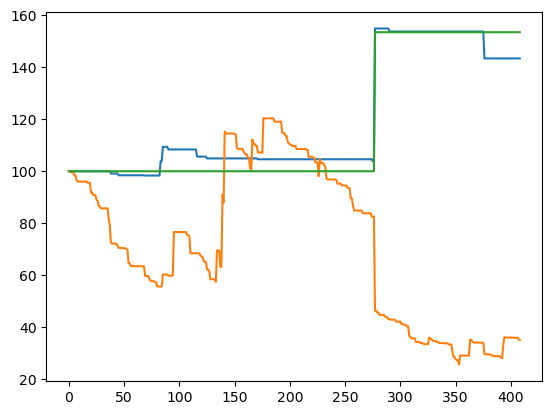

In [955]:
threshold = 0.05
performance(strategy = kelly, 
            proba_mat = pred_proba_test_clogit, 
            odds_mat = win_odds_test, 
            y_mat = (y_test == 1), threshold = threshold)
performance(strategy = kelly, 
            proba_mat = pred_proba_test_deeplogit, 
            odds_mat = win_odds_test, 
            y_mat = (y_test == 1), threshold = threshold)
performance(strategy = kelly, 
            proba_mat = pred_proba_test_ttlogit, 
            odds_mat = win_odds_test, 
            y_mat = (y_test == 1), threshold = threshold)

In [936]:
def kelly(proba, odds, amount, threshold = 0, partial = 1.0):
    advantage = proba*odds-1
    tt = odds[odds > 0]
    tt = 1 - 1/sum(1/tt)
    implied_proba = (1-tt)/(odds + 1e-6)
    implied_proba = implied_proba*(odds>0)
    proba_ratio = proba*odds/(1-tt)
    order = np.argsort(proba_ratio)[::-1]
    beta = 1 - proba[order].cumsum()
    beta_public = 1 - implied_proba[order].cumsum()
    condition1 = (1 - beta_public)/(1 - beta) <= 1 - tt
    rhs = beta/(beta_public - tt)
    out = np.zeros_like(order, dtype = float)
    ordered_out = np.zeros_like(order)
    for i in np.where(condition1)[0]:
        proportion = proba[order][:i+1] - implied_proba[order][:i+1]*rhs[i]
        if (proportion > 0).all() == False:
            break
        ordered_out = proportion
    out[order] = np.pad(ordered_out, (0,len(order)-len(ordered_out)))
    return amount[-1]*partial*out*(advantage > threshold)

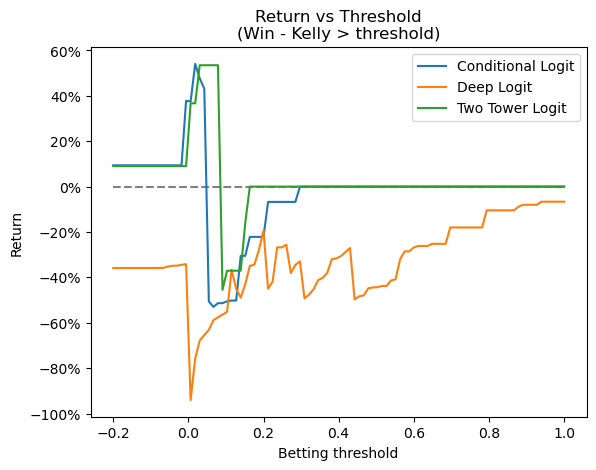

In [948]:
strategy = kelly
odds_mat = win_odds_test
y_mat = (y_test == 1)
proba_candidates = [pred_proba_test_clogit, pred_proba_test_deeplogit, pred_proba_test_ttlogit]
threshold_grid = np.linspace(-0.2,1,100)
result_win = [compare_threshold(strategy, proba_mat, odds_mat, y_mat, threshold_grid) for proba_mat in proba_candidates]
plt.plot([-0.2,1], [0,0], linestyle = '--', color = "gray")
plt.plot(threshold_grid, result_win[0], label = "Conditional Logit")
plt.plot(threshold_grid, result_win[1], label = "Deep Logit")
plt.plot(threshold_grid, result_win[2], label = "Two Tower Logit")
plt.ylabel("Return")
plt.xlabel("Betting threshold")
plt.title("Return vs Threshold\n(Win - Kelly > threshold)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend()

In [934]:
result_win

[[0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.09384723415667007,
  0.0938472

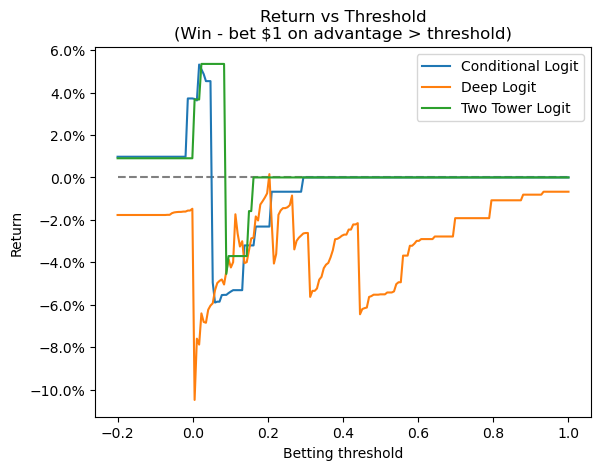

In [938]:
strategy = fixed_among_positive_advantage
odds_mat = win_odds_test
y_mat = (y_test == 1)
proba_candidates = [pred_proba_test_clogit, pred_proba_test_deeplogit, pred_proba_test_ttlogit]
threshold_grid = np.linspace(-0.2,1,200)
result_win = [compare_threshold(strategy, proba_mat, odds_mat, y_mat, threshold_grid) for proba_mat in proba_candidates]
plt.plot([-0.2,1], [0,0], linestyle = '--', color = "gray")
plt.plot(threshold_grid, result_win[0], label = "Conditional Logit")
plt.plot(threshold_grid, result_win[1], label = "Deep Logit")
plt.plot(threshold_grid, result_win[2], label = "Two Tower Logit")
plt.ylabel("Return")
plt.xlabel("Betting threshold")
plt.title("Return vs Threshold\n(Win - bet $1 on advantage > threshold)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend()

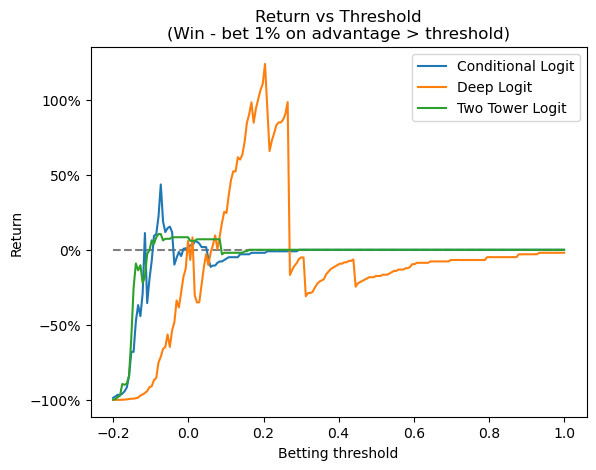

In [663]:
strategy = fixed_proportion_among_positive_advantage
odds_mat = win_odds_test
y_mat = (y_test == 1)
proba_candidates = [pred_proba_test_clogit, pred_proba_test_deeplogit, pred_proba_test_ttlogit]
threshold_grid = np.linspace(-0.2,1,200)
result_win = [compare_threshold(strategy, proba_mat, odds_mat, y_mat, threshold_grid) for proba_mat in proba_candidates]
plt.plot([-0.2,1], [0,0], linestyle = '--', color = "gray")
plt.plot(threshold_grid, result_win[0], label = "Conditional Logit")
plt.plot(threshold_grid, result_win[1], label = "Deep Logit")
plt.plot(threshold_grid, result_win[2], label = "Two Tower Logit")
plt.ylabel("Return")
plt.xlabel("Betting threshold")
plt.title("Return vs Threshold\n(Win - bet 1% on advantage > threshold)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend()

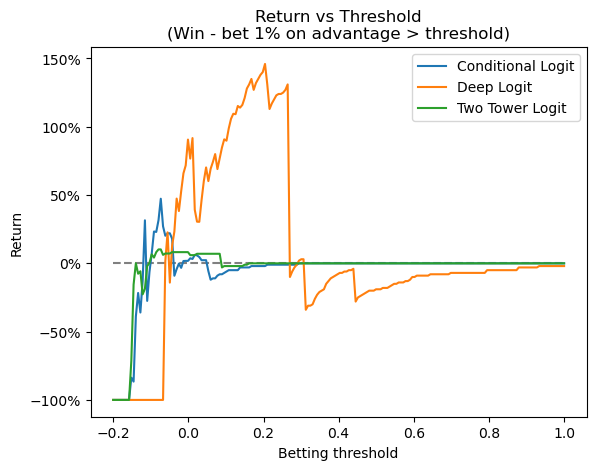

In [662]:
plt.plot([-0.2,1], [0,0], linestyle = '--', color = "gray")
plt.plot(threshold_grid, result_win[0], label = "Conditional Logit")
plt.plot(threshold_grid, result_win[1], label = "Deep Logit")
plt.plot(threshold_grid, result_win[2], label = "Two Tower Logit")
plt.ylabel("Return")
plt.xlabel("Betting threshold")
plt.title("Return vs Threshold\n(Win - bet 1% on advantage > threshold)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend()

# Place, Quinella and Quinella Place

In [542]:
pred_p_proba_test_clogit, y_p_test, pred_q_proba_test_clogit, y_q_test, pred_qp_proba_test_clogit, y_qp_test = generate_other_pools(pred_proba_test_clogit, y_test, place_odds_test, q_odds_test, qp_odds_test)
pred_p_proba_test_deeplogit, y_p_test, pred_q_proba_test_deeplogit, y_q_test, pred_qp_proba_test_deeplogit, y_qp_test = generate_other_pools(pred_proba_test_deeplogit, y_test, place_odds_test, q_odds_test, qp_odds_test)
pred_p_proba_test_ttlogit, y_p_test, pred_q_proba_test_ttlogit, y_q_test, pred_qp_proba_test_ttlogit, y_qp_test = generate_other_pools(pred_proba_test_ttlogit, y_test, place_odds_test, q_odds_test, qp_odds_test)

In [584]:
def compare_threshold(strategy, proba_mat, odds_mat, y_mat, threshold_grid, **kwargs):
    result = []
    for threshold in threshold_grid:
        amounts = performance(strategy = strategy, 
                            proba_mat = proba_mat, 
                            odds_mat = odds_mat, 
                            y_mat = y_mat, threshold = threshold, return_mode = "result", **kwargs)[0]
        result.append(amounts[-1]/amounts[0] - 1)
    return result

In [630]:
strategy = fixed_among_positive_advantage
odds_mat = place_odds_test.to_numpy()
y_mat = y_p_test
proba_candidates = [pred_p_proba_test_clogit, pred_p_proba_test_deeplogit, pred_p_proba_test_ttlogit]
threshold_grid = np.linspace(0,1,200)
result_place = [compare_threshold(strategy, proba_mat, odds_mat, y_mat, threshold_grid) for proba_mat in proba_candidates]

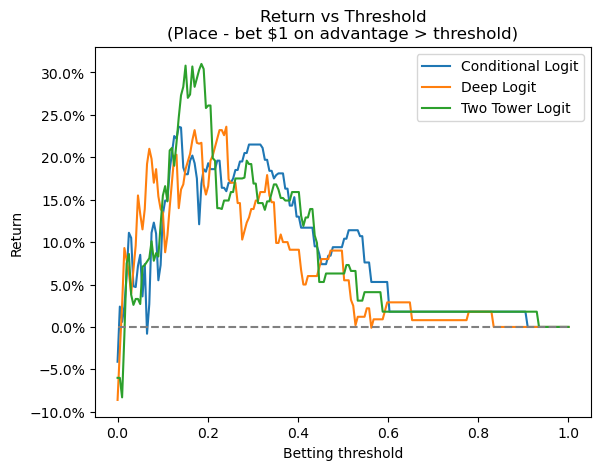

In [631]:
plt.plot(threshold_grid, result_place[0], label = "Conditional Logit")
plt.plot(threshold_grid, result_place[1], label = "Deep Logit")
plt.plot(threshold_grid, result_place[2], label = "Two Tower Logit")
plt.plot([0,1], [0,0], linestyle = '--', color = "gray")
plt.ylabel("Return")
plt.xlabel("Betting threshold")
plt.title("Return vs Threshold\n(Place - bet $1 on advantage > threshold)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend()

In [632]:
strategy = fixed_proportion_among_positive_advantage
odds_mat = place_odds_test.to_numpy()
y_mat = y_p_test
proba_candidates = [pred_p_proba_test_clogit, pred_p_proba_test_deeplogit, pred_p_proba_test_ttlogit]
threshold_grid = np.linspace(0,1,200)
result_place = [compare_threshold(strategy, proba_mat, odds_mat, y_mat, threshold_grid) for proba_mat in proba_candidates]

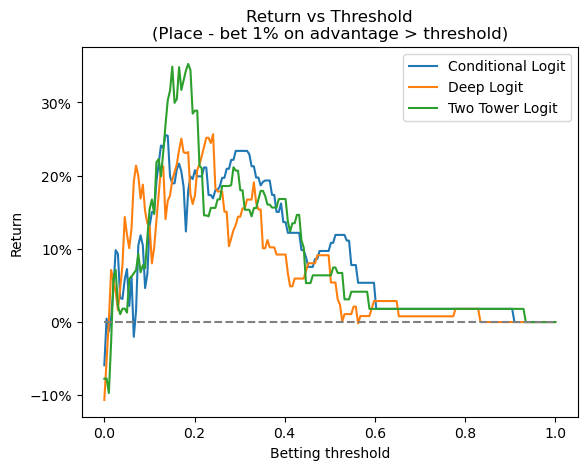

In [637]:
plt.plot(threshold_grid, result_place[0], label = "Conditional Logit")
plt.plot(threshold_grid, result_place[1], label = "Deep Logit")
plt.plot(threshold_grid, result_place[2], label = "Two Tower Logit")
plt.plot([0,1], [0,0], linestyle = '--', color = "gray")
plt.ylabel("Return")
plt.xlabel("Betting threshold")
plt.title("Return vs Threshold\n(Place - bet 1% on advantage > threshold)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend()

## Quinella

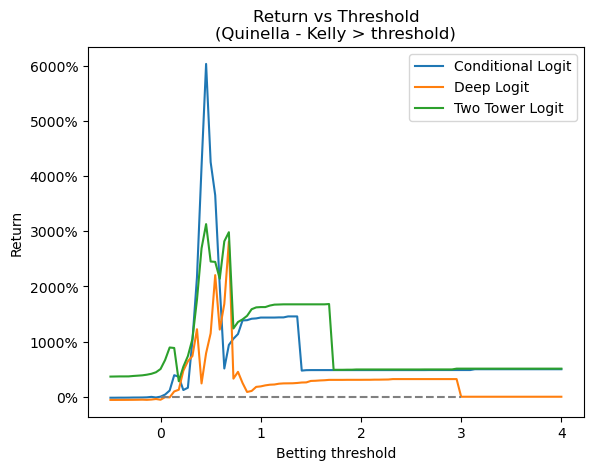

In [947]:
strategy = kelly
odds_mat = q_odds_test.to_numpy()
y_mat = y_q_test
proba_candidates = [pred_q_proba_test_clogit, pred_q_proba_test_deeplogit, pred_q_proba_test_ttlogit]
threshold_grid = np.linspace(-0.5, 4, 100)
result_q = [compare_threshold(strategy, proba_mat, odds_mat, y_mat, threshold_grid) for proba_mat in proba_candidates]
plt.plot(threshold_grid, result_q[0], label = "Conditional Logit")
plt.plot(threshold_grid, result_q[1], label = "Deep Logit")
plt.plot(threshold_grid, result_q[2], label = "Two Tower Logit")
plt.plot([0,3], [0,0], linestyle = '--', color = "gray")
plt.ylabel("Return")
plt.xlabel("Betting threshold")
plt.title("Return vs Threshold\n(Quinella - Kelly > threshold)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend()

In [638]:
strategy = fixed_among_positive_advantage
odds_mat = q_odds_test.to_numpy()
y_mat = y_q_test
proba_candidates = [pred_q_proba_test_clogit, pred_q_proba_test_deeplogit, pred_q_proba_test_ttlogit]
threshold_grid = np.linspace(0, 4, 400)
result_q = [compare_threshold(strategy, proba_mat, odds_mat, y_mat, threshold_grid) for proba_mat in proba_candidates]

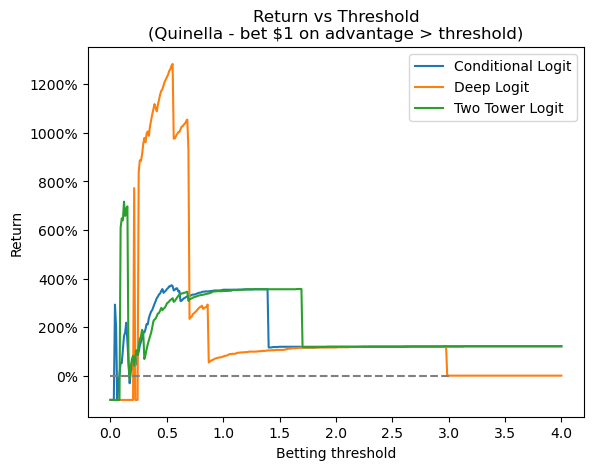

In [641]:
plt.plot(threshold_grid, result_q[0], label = "Conditional Logit")
plt.plot(threshold_grid, result_q[1], label = "Deep Logit")
plt.plot(threshold_grid, result_q[2], label = "Two Tower Logit")
plt.plot([0,3], [0,0], linestyle = '--', color = "gray")
plt.ylabel("Return")
plt.xlabel("Betting threshold")
plt.title("Return vs Threshold\n(Quinella - bet $1 on advantage > threshold)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend()

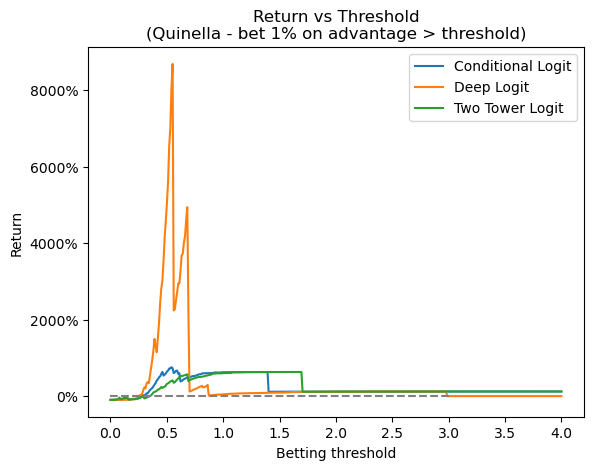

In [643]:
strategy = fixed_proportion_among_positive_advantage
odds_mat = q_odds_test.to_numpy()
y_mat = y_q_test
proba_candidates = [pred_q_proba_test_clogit, pred_q_proba_test_deeplogit, pred_q_proba_test_ttlogit]
threshold_grid = np.linspace(0, 4, 400)
result_q = [compare_threshold(strategy, proba_mat, odds_mat, y_mat, threshold_grid) for proba_mat in proba_candidates]
plt.plot(threshold_grid, result_q[0], label = "Conditional Logit")
plt.plot(threshold_grid, result_q[1], label = "Deep Logit")
plt.plot(threshold_grid, result_q[2], label = "Two Tower Logit")
plt.plot([0,3], [0,0], linestyle = '--', color = "gray")
plt.ylabel("Return")
plt.xlabel("Betting threshold")
plt.title("Return vs Threshold\n(Quinella - bet 1% on advantage > threshold)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend()

## Quinella Place

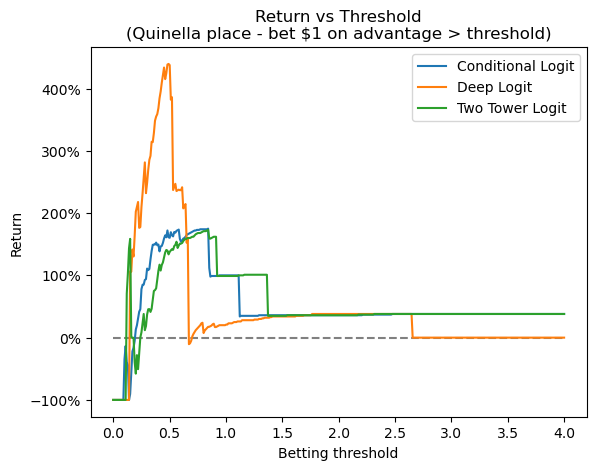

In [646]:
strategy = fixed_among_positive_advantage
odds_mat = qp_odds_test.to_numpy()
y_mat = y_qp_test
proba_candidates = [pred_qp_proba_test_clogit, pred_qp_proba_test_deeplogit, pred_qp_proba_test_ttlogit]
threshold_grid = np.linspace(0, 4, 400)
result_qp = [compare_threshold(strategy, proba_mat, odds_mat, y_mat, threshold_grid) for proba_mat in proba_candidates]
plt.plot([0,4], [0,0], linestyle = '--', color = "gray")
plt.plot(threshold_grid, result_qp[0], label = "Conditional Logit")
plt.plot(threshold_grid, result_qp[1], label = "Deep Logit")
plt.plot(threshold_grid, result_qp[2], label = "Two Tower Logit")
plt.ylabel("Return")
plt.xlabel("Betting threshold")
plt.title("Return vs Threshold\n(Quinella place - bet $1 on advantage > threshold)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend()

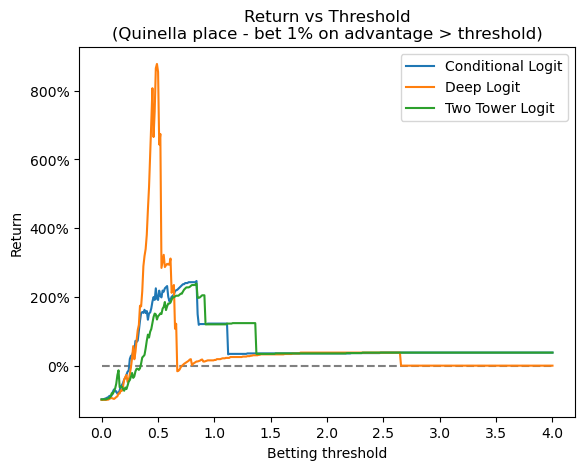

In [647]:
strategy = fixed_proportion_among_positive_advantage
odds_mat = qp_odds_test.to_numpy()
y_mat = y_qp_test
proba_candidates = [pred_qp_proba_test_clogit, pred_qp_proba_test_deeplogit, pred_qp_proba_test_ttlogit]
threshold_grid = np.linspace(0, 4, 400)
result_qp = [compare_threshold(strategy, proba_mat, odds_mat, y_mat, threshold_grid) for proba_mat in proba_candidates]
plt.plot([0,4], [0,0], linestyle = '--', color = "gray")
plt.plot(threshold_grid, result_qp[0], label = "Conditional Logit")
plt.plot(threshold_grid, result_qp[1], label = "Deep Logit")
plt.plot(threshold_grid, result_qp[2], label = "Two Tower Logit")
plt.ylabel("Return")
plt.xlabel("Betting threshold")
plt.title("Return vs Threshold\n(Quinella place - bet 1% on advantage > threshold)")
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))
plt.legend()